In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/lung_cancer_dataset.csv')
df.head()


,Patient_ID,Diagnosis_Year,Diagnosis_Date,WHO_Region,Country,Age,Age_Group,Gender,Smoking_Status,Cigarettes_Per_Day,...,Symptom_Count,Cancer_Type,NSCLC_Subtype,Cancer_Stage,Tumor_Size_cm,Metastasis,Diagnosis_Method,Treatment,Survival_Months,Survived
0,LC-0001,2020,2020-11-04,Western Pacific,China,46,40-49,Female,Current Smoker,28,...,5,NSCLC,Adenocarcinoma,Stage IV,6.4,Yes,MRI,Chemo + Radiation,4,No
1,LC-0002,2021,2021-12-09,Americas,Mexico,71,70-79,Male,Former Smoker,5,...,5,NSCLC,Adenocarcinoma,Stage I,2.6,No,Biopsy,Surgery + Chemotherapy,76,Yes
2,LC-0003,2017,2017-04-05,Western Pacific,Japan,53,50-59,Female,Never Smoked,0,...,3,NSCLC,Squamous Cell,Stage I,2.9,No,LDCT Screening,Surgery,69,No
3,LC-0004,2018,2018-11-24,Western Pacific,Singapore,55,50-59,Male,Current Smoker,21,...,6,NSCLC,Adenocarcinoma,Stage IV,7.0,Yes,CT Scan,Chemotherapy,9,No
4,LC-0005,2024,2024-02-19,Western Pacific,Malaysia,54,50-59,Male,Never Smoked,0,...,5,NSCLC,Adenocarcinoma,Stage III,5.8,No,Bronchoscopy,Immunotherapy,5,Yes


In [ ]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null values
print("\nDataset information:")
df.info()

# Statistical summary
print("\nStatistical summary:")
display(df.describe(include='all').T)

Dataset shape: (2000, 46)

Column names:
['Patient_ID', 'Diagnosis_Year', 'Diagnosis_Date', 'WHO_Region', 'Country', 'Age', 'Age_Group', 'Gender', 'Smoking_Status', 'Cigarettes_Per_Day', 'Years_Smoking', 'Pack_Years', 'Secondhand_Smoke', 'Family_History', 'Occupational_Hazard', 'Air_Pollution_Exposure', 'Alcohol_Use', 'BMI', 'BMI_Category', 'Exercise_Frequency', 'Chronic_Lung_Disease', 'Asbestos_Exposure', 'Radon_Exposure', 'Previous_Cancer_History', 'Risk_Factor_Count', 'Genetic_Mutation', 'Coughing', 'Shortness_of_Breath', 'Chest_Pain', 'Coughing_Blood', 'Fatigue', 'Weight_Loss', 'Wheezing', 'Recurrent_Infections', 'Swallowing_Difficulty', 'Finger_Clubbing', 'Symptom_Count', 'Cancer_Type', 'NSCLC_Subtype', 'Cancer_Stage', 'Tumor_Size_cm', 'Metastasis', 'Diagnosis_Method', 'Treatment', 'Survival_Months', 'Survived']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 46 columns):
 #   Column                   Non-Null Cou

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Patient_ID,2000,2000,LC-1984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Diagnosis_Year,2000.0,NaN,NaN,NaN,2021.262,3.279746,2015.0,2019.0,2022.0,2024.0,2026.0
Diagnosis_Date,2000,1520,2026-07-07,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WHO_Region,2000,6,Western Pacific,631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,2000,60,Japan,74,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2000.0,NaN,NaN,NaN,60.749,10.337235,30.0,53.0,60.0,68.0,89.0
Age_Group,2000,6,50-59,657,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,2000,2,Male,1248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Smoking_Status,2000,3,Never Smoked,1311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cigarettes_Per_Day,2000.0,NaN,NaN,NaN,7.274,11.673734,0.0,0.0,0.0,14.0,56.0


In [ ]:
# Step 3: Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check target column
print("\nTarget column distribution:")
print(df['Survived'].value_counts())

# Check target percentages
print("\nTarget percentage:")
print(df['Survived'].value_counts(normalize=True) * 100)

# Check unique values in categorical columns
print("\nSurvived unique values:")
print(df['Survived'].unique())

Missing values in each column:
Patient_ID                 0
Diagnosis_Year             0
Diagnosis_Date             0
WHO_Region                 0
Country                    0
Age                        0
Age_Group                  0
Gender                     0
Smoking_Status             0
Cigarettes_Per_Day         0
Years_Smoking              0
Pack_Years                 0
Secondhand_Smoke           0
Family_History             0
Occupational_Hazard        0
Air_Pollution_Exposure     0
Alcohol_Use                0
BMI                        0
BMI_Category               0
Exercise_Frequency         0
Chronic_Lung_Disease       0
Asbestos_Exposure          0
Radon_Exposure             0
Previous_Cancer_History    0
Risk_Factor_Count          0
Genetic_Mutation           0
Coughing                   0
Shortness_of_Breath        0
Chest_Pain                 0
Coughing_Blood             0
Fatigue                    0
Weight_Loss                0
Wheezing                   0
Recurrent_In

Survived
No     1244
Yes     756
Name: count, dtype: int64


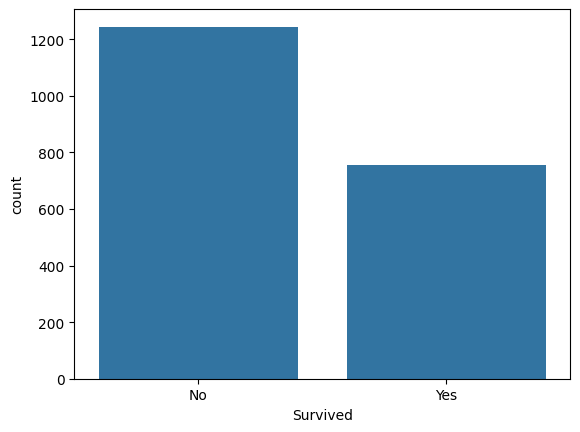

In [ ]:
print(df['Survived'].value_counts())

sns.countplot(data=df, x='Survived')
plt.show()

In [ ]:
print(df.select_dtypes(include='object').nunique())

Patient_ID                 2000
Diagnosis_Date             1520
WHO_Region                    6
Country                      60
Age_Group                     6
Gender                        2
Smoking_Status                3
Secondhand_Smoke              2
Family_History                2
Occupational_Hazard           2
Air_Pollution_Exposure        3
Alcohol_Use                   3
BMI_Category                  4
Exercise_Frequency            3
Chronic_Lung_Disease          2
Asbestos_Exposure             2
Radon_Exposure                2
Previous_Cancer_History       2
Genetic_Mutation             10
Coughing                      2
Shortness_of_Breath           2
Chest_Pain                    2
Coughing_Blood                2
Fatigue                       2
Weight_Loss                   2
Wheezing                      2
Recurrent_Infections          2
Swallowing_Difficulty         2
Finger_Clubbing               2
Cancer_Type                   2
NSCLC_Subtype                 4
Cancer_S

In [ ]:
df = df.drop(columns=['Patient_ID', 'Diagnosis_Date'])
print(df.shape)

(2000, 44)


In [ ]:
print(df.dtypes)

Diagnosis_Year               int64
WHO_Region                  object
Country                     object
Age                          int64
Age_Group                   object
Gender                      object
Smoking_Status              object
Cigarettes_Per_Day           int64
Years_Smoking                int64
Pack_Years                 float64
Secondhand_Smoke            object
Family_History              object
Occupational_Hazard         object
Air_Pollution_Exposure      object
Alcohol_Use                 object
BMI                        float64
BMI_Category                object
Exercise_Frequency          object
Chronic_Lung_Disease        object
Asbestos_Exposure           object
Radon_Exposure              object
Previous_Cancer_History     object
Risk_Factor_Count            int64
Genetic_Mutation            object
Coughing                    object
Shortness_of_Breath         object
Chest_Pain                  object
Coughing_Blood              object
Fatigue             

In [ ]:
df = df.drop(columns=['Survival_Months'])

In [ ]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [ ]:
y = y.map({'No': 0, 'Yes': 1})

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(1600, 42) (400, 42)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(include='object').columns

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import accuracy_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'SVM': SVC(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Naive Bayes': GaussianNB(),
    'AdaBoost': AdaBoostClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessing', clone(preprocessor)),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append([name, accuracy_score(y_test, pred)])

results_df = pd.DataFrame(results, columns=['Algorithm', 'Accuracy'])
print(results_df.sort_values('Accuracy', ascending=False))

             Algorithm  Accuracy
6             AdaBoost    0.6950
7    Gradient Boosting    0.6875
0  Logistic Regression    0.6850
2                  SVM    0.6825
4        Random Forest    0.6800
1                  KNN    0.6750
3        Decision Tree    0.6650
5          Naive Bayes    0.6575


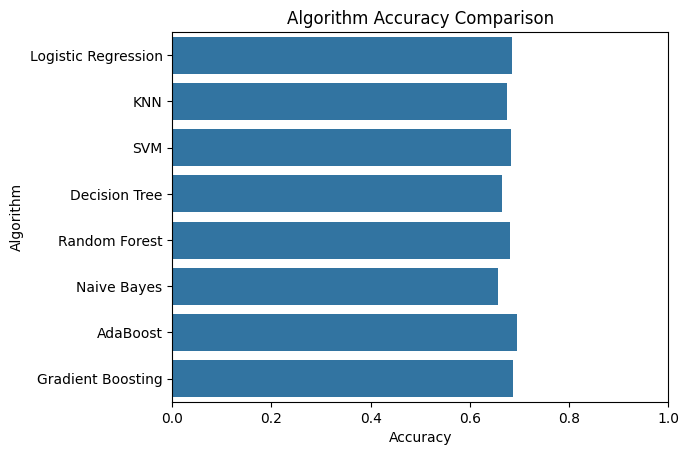

In [ ]:
sns.barplot(data=results_df, x='Accuracy', y='Algorithm')
plt.title('Algorithm Accuracy Comparison')
plt.xlim(0, 1)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessing', clone(preprocessor)),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    print("\n", name)
    print(classification_report(y_test, pred, target_names=['No', 'Yes']))


 Logistic Regression
              precision    recall  f1-score   support

          No       0.77      0.70      0.73       249
         Yes       0.57      0.66      0.61       151

    accuracy                           0.69       400
   macro avg       0.67      0.68      0.67       400
weighted avg       0.70      0.69      0.69       400


 KNN
              precision    recall  f1-score   support

          No       0.75      0.72      0.73       249
         Yes       0.57      0.60      0.58       151

    accuracy                           0.68       400
   macro avg       0.66      0.66      0.66       400
weighted avg       0.68      0.68      0.68       400


 SVM
              precision    recall  f1-score   support

          No       0.76      0.72      0.74       249
         Yes       0.57      0.62      0.60       151

    accuracy                           0.68       400
   macro avg       0.67      0.67      0.67       400
weighted avg       0.69      0.68      0

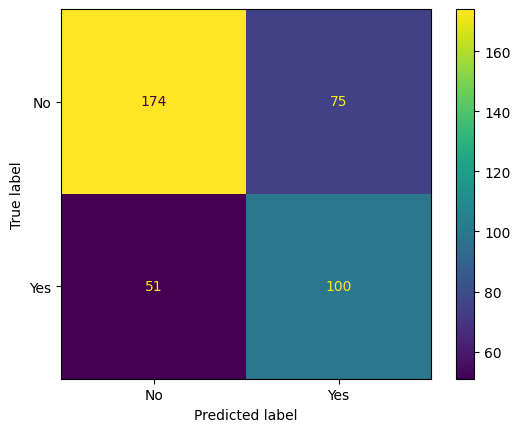

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

best_model = Pipeline([
    ('preprocessing', clone(preprocessor)),
    ('model', LogisticRegression(max_iter=1000))
])

best_model.fit(X_train, y_train)

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test,
    display_labels=['No', 'Yes']
)
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessing', clone(preprocessor)),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0)
    ])

results_df = pd.DataFrame(
    results,
    columns=['Algorithm', 'Accuracy', 'Precision', 'Recall', 'F1-score']
)

print(results_df.round(3).sort_values('F1-score', ascending=False))

             Algorithm  Accuracy  Precision  Recall  F1-score
0  Logistic Regression     0.685      0.571   0.662     0.613
7    Gradient Boosting     0.688      0.577   0.642     0.608
5          Naive Bayes     0.658      0.536   0.689     0.603
6             AdaBoost     0.695      0.594   0.609     0.601
2                  SVM     0.682      0.573   0.623     0.597
4        Random Forest     0.680      0.572   0.603     0.587
1                  KNN     0.675      0.566   0.596     0.581
3        Decision Tree     0.665      0.558   0.543     0.550


In [ ]:
df['Survived_num'] = df['Survived'].map({'No': 0, 'Yes': 1})

print(df.corr(numeric_only=True)['Survived_num'].sort_values(ascending=False))

Survived_num          1.000000
Diagnosis_Year        0.021048
Risk_Factor_Count     0.008233
Age                   0.006262
BMI                  -0.015792
Symptom_Count        -0.090063
Pack_Years           -0.118341
Years_Smoking        -0.124127
Cigarettes_Per_Day   -0.127596
Tumor_Size_cm        -0.436310
Name: Survived_num, dtype: float64


In [ ]:
print(df.groupby('Survived')['Tumor_Size_cm'].mean())

Survived
No     5.354662
Yes    3.220767
Name: Tumor_Size_cm, dtype: float64


In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    scores = cross_val_score(
        pipeline, X, y,
        cv=cv,
        scoring='accuracy'
    )

    results.append({
        'Algorithm': name,
        'Mean Accuracy (%)': round(scores.mean() * 100, 2),
        'Std Deviation (%)': round(scores.std() * 100, 2)
    })

cv_results = pd.DataFrame(results)
print(cv_results.sort_values('Mean Accuracy (%)', ascending=False))

             Algorithm  Mean Accuracy (%)  Std Deviation (%)
6             AdaBoost              72.40               2.03
2                  SVM              71.75               2.22
4        Random Forest              71.65               3.36
7    Gradient Boosting              71.20               1.72
0  Logistic Regression              70.40               1.85
1                  KNN              67.80               3.44
3        Decision Tree              66.10               1.42
5          Naive Bayes              64.90               2.51


In [ ]:
best_model = cv_results.loc[
    cv_results['Mean Accuracy (%)'].idxmax()
]

print("Best Model:", best_model['Algorithm'])
print("Mean Accuracy:", best_model['Mean Accuracy (%)'], "%")
print("Standard Deviation:", best_model['Std Deviation (%)'], "%")

Best Model: AdaBoost
Mean Accuracy: 72.4 %
Standard Deviation: 2.03 %
